# Phase 2: Feature selection

**BOD Prediction — Bangladesh water-quality dataset**

Phase 2 fixes the predictor representation that every later phase uses, and writes it to `phase2_manifest.json`. Phase 3 reads the lock from that file rather than from `config.PRIMARY_FEATURES`.

### Sequence
1. **2.1 EC vs TDS** — FS-A (EC) against FS-B (TDS) at equal complexity, then FS-C (both) and FS-E (fold-safe PC1 of log EC/TDS) against the winner under the parsimony rule. This fixes the chemistry **and the analysis population**: an EC-based lock is analysed on DS-3F, a TDS-based lock on DS-4F.
2. **2.2 Temporal information** — month-only, season-only, chemistry-only, and chemistry + {month dummies, season, cyclic month}, all on the locked population. A temporal representation is added only if it passes the joint LOSO-River + Forward-Chain rule.
3. **2.3 Transformation robustness** — the log representation is fixed a priori; raw chemistry is reported as a robustness check, not used to choose.
4. **2.4 Lock and hand-off.**

### Analysis rules
- Decisions use the **pre-specified metric**: the unweighted mean of per-fold R² on the log scale. The n-weighted mean and pooled out-of-fold R² are reported alongside for transparency and never change a decision.
- All preprocessing (scaling, PCA) is refit inside each inner fold — `src.models.tune` wraps the whole pipeline in `GridSearchCV`.
- `log_BOD = log1p(BOD)`; the inverse is `expm1`.


In [1]:
# 0. Environment
# Setup. `pip install -e .` from the repository root makes `src` importable (README);
# without it, the repository root (the parent of notebooks/) is added to the path.
try:
    import src  # noqa: F401
except ModuleNotFoundError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(Path.cwd().resolve().parent))

import sys
import json
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone

from src.config import *
from src.data_loading import load_locked_dataset
from src.folds import build_loso_river, build_fc, inner_cv_for_folds
from src.evaluation import evaluate_model_oof, summarize_with_pooled
from src.models import fit_ridge_scaled, fit_ridge_cv
from src.preprocessing import inspect_pca_block, pca_block_feature_names
from src.stats import vif

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

ds3 = load_locked_dataset("DS-3F").reset_index(drop=True)
ds4 = load_locked_dataset("DS-4F").reset_index(drop=True)
DATASETS = {"DS-3F": ds3, "DS-4F": ds4}

print("DS-3F:", ds3.shape)
print("DS-4F:", ds4.shape)
print("Primary target:", PRIMARY_TARGET)
print("Primary threshold:", PRIMARY_THRESHOLD, "mg/L")
print("config.PRIMARY_FEATURES:", list(PRIMARY_FEATURES), "(not used here; Phase 2 decides the lock)")

DS-3F: (1131, 48)
DS-4F: (1083, 48)
Primary target: log_BOD
Primary threshold: 6 mg/L
config.PRIMARY_FEATURES: ['log_EC', 'pH', 'log1p_DO'] (not used here; Phase 2 decides the lock)


In [2]:
# Ridge alpha grid comes from src/config.py (RIDGE_ALPHAS); Phase 3 asserts it
# uses the same list. Evaluation is src.evaluation.evaluate_model_oof — the same
# code path as evaluate_model — which also returns out-of-fold predictions.
print("RIDGE_ALPHAS:", list(RIDGE_ALPHAS))

def fold_pivot(fold_frames, value="R2_log", key="spec"):
    """Rows = folds, columns = specs; appends unweighted and n-weighted means."""
    long = pd.concat(fold_frames, ignore_index=True)
    piv = long.pivot(index="fold", columns=key, values=value)
    n = long.groupby("fold")["n"].first().reindex(piv.index)
    piv.insert(0, "n", n)
    specs = [c for c in piv.columns if c != "n"]
    folds_only = piv[specs].iloc[: len(n)]
    piv.loc["mean (unweighted)", specs] = folds_only.mean()
    piv.loc["mean (n-weighted)", specs] = folds_only.mul(n, axis=0).sum() / n.sum()
    return piv

RIDGE_ALPHAS: [0.01, 0.1, 1.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0, 10000.0]


## 2.1 EC versus TDS

EC and TDS both track dissolved ionic load, so they are expected to be strongly collinear; 2.1a computes their correlation and VIF. The candidates, all on DS-4F — the only population where TDS exists — are:

- **FS-A:** EC + pH + DO
- **FS-B:** TDS + pH + DO
- **FS-C:** EC + TDS + pH + DO
- **FS-E:** log EC + log TDS + pH + log1p DO, with EC/TDS collapsed to a **fold-safe PC1** (`pca_block="PC1_EC_TDS"`)

The PCA diagnostic below is descriptive. For two standardised variables, PC1 loadings are always ±0.7071, so only the explained-variance ratio carries information.

In [3]:
# 2.1a — EC/TDS correlation and VIF
d4 = ds4[["log_EC", "log_TDS", "pH", "log1p_DO", "log_BOD"]].dropna().copy()

ec_tds_corr = d4["log_EC"].corr(d4["log_TDS"])
print(f"Pearson r(log_EC, log_TDS) = {ec_tds_corr:.4f}")

vif_all = vif(d4, ["log_EC", "log_TDS", "pH", "log1p_DO"])
display(vif_all)
vif_all.to_csv(RESULTS_DIR / "phase2_ec_tds_vif.csv", index=False)

pca_diag = inspect_pca_block(ds4, ["log_EC", "log_TDS", "pH", "log1p_DO"], "PC1_EC_TDS")
display(pca_diag)
pca_diag.to_csv(RESULTS_DIR / "phase2_pc1_ec_tds_diagnostic.csv")

Pearson r(log_EC, log_TDS) = 0.9784


,feature,VIF
0,log_EC,23.9000
1,log_TDS,23.7000
2,pH,1.1000
3,log1p_DO,2.4000


,log_EC,log_TDS
PC1 (EVR=0.989),0.7071,0.7071


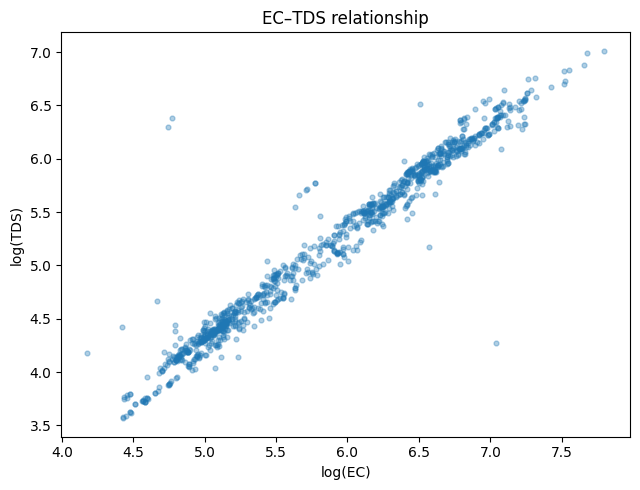

In [4]:
# 2.1b — visualise EC/TDS relationship
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(d4["log_EC"], d4["log_TDS"], s=12, alpha=0.35)
ax.set_xlabel("log(EC)")
ax.set_ylabel("log(TDS)")
ax.set_title("EC–TDS relationship")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase2_ec_tds_relationship.png", dpi=300, bbox_inches="tight")
plt.show()

In [5]:
# 2.1c — predictive comparison under LOSO-River (Ridge, identical folds)
# The decision is taken on the LOG representation that gets locked
# (config.FEATURE_CONFIGS_LOG); the raw sets (FEATURE_CONFIGS) are a descriptive check.
EC_TDS_SETS = ["FS-A", "FS-B", "FS-C", "FS-E"]

loso4 = build_loso_river(ds4)
inner_cv4, inner_group4 = inner_cv_for_folds(ds4, loso4, "loso_river")

fs_rows, fs_fold_frames, fs_raw_fold_frames = [], [], []
for representation, configs in [("log", FEATURE_CONFIGS_LOG), ("raw", FEATURE_CONFIGS)]:
    for label in EC_TDS_SETS:
        cfg = configs[label]
        feats, pca = list(cfg["cols"]), cfg.get("pca_block")
        assert ds4[feats].notna().all().all(), f"{label}: missing predictor values in DS-4F"
        model = fit_ridge_cv(feats, inner_cv4, pca_block=pca)
        fdf, oof = evaluate_model_oof(model, ds4, feats, "log_BOD", loso4,
                                      threshold=PRIMARY_THRESHOLD, inner_group_col=inner_group4)
        name = label if representation == "log" else f"{label} (raw)"
        fdf["spec"] = name
        (fs_fold_frames if representation == "log" else fs_raw_fold_frames).append(fdf)
        s = summarize_with_pooled(fdf, oof, name, PRIMARY_THRESHOLD)
        s.update(features=", ".join(feats), pca_block=pca or "", dataset="DS-4F",
                 representation=representation, role="decision" if representation == "log" else "descriptive")
        fs_rows.append(s)

# Population check (not part of the decision): FS-A on DS-3F, which keeps the
# rows DS-4F drops for missing TDS.
loso3 = build_loso_river(ds3)
inner_cv3, inner_group3 = inner_cv_for_folds(ds3, loso3, "loso_river")
feats_a = list(FEATURE_CONFIGS_LOG["FS-A"]["cols"])
fdf, oof = evaluate_model_oof(fit_ridge_cv(feats_a, inner_cv3), ds3, feats_a, "log_BOD", loso3,
                              threshold=PRIMARY_THRESHOLD, inner_group_col=inner_group3)
s = summarize_with_pooled(fdf, oof, "FS-A on DS-3F (population check)", PRIMARY_THRESHOLD)
s.update(features=", ".join(feats_a), pca_block="", dataset="DS-3F", representation="log", role="population check")
fs_rows.append(s)

fs_ridge_summary = pd.DataFrame(fs_rows).set_index("label")
show = ["representation", "role", "dataset", "features", "pca_block", "n_folds", "R2_log_mean", "R2_log_sd",
        "R2_log_wmean", "R2_log_pooled", "MAE_mgL_pooled", "RMSE_mgL_pooled"]
display(fs_ridge_summary[show])

fs_fold_table = fold_pivot(fs_fold_frames)
print("Per-fold R² (log scale), DS-4F:")
display(fs_fold_table.round(3))

fs_ridge_summary.to_csv(RESULTS_DIR / "phase2_ec_tds_ridge_loso_summary.csv")
pd.concat(fs_fold_frames, ignore_index=True).to_csv(
    RESULTS_DIR / "phase2_ec_tds_ridge_loso_fold_results.csv", index=False
)
fs_fold_table.to_csv(RESULTS_DIR / "phase2_ec_tds_per_fold_r2.csv")
fs_raw_fold_table = fold_pivot(fs_raw_fold_frames)
print("Per-fold R² (log scale), raw representation (descriptive only):")
display(fs_raw_fold_table.round(3))
fs_raw_fold_table.to_csv(RESULTS_DIR / "phase2_ec_tds_per_fold_r2_raw.csv")

,representation,role,dataset,features,pca_block,n_folds,R2_log_mean,R2_log_sd,R2_log_wmean,R2_log_pooled,MAE_mgL_pooled,RMSE_mgL_pooled
label,,,,,,,,,,,,
FS-A,log,decision,DS-4F,"log_EC, pH, log1p_DO",,5,0.5412,0.0979,0.5046,0.5433,6.0768,10.0105
FS-B,log,decision,DS-4F,"log_TDS, pH, log1p_DO",,5,0.5449,0.0889,0.5140,0.5510,6.0040,9.9291
FS-C,log,decision,DS-4F,"log_EC, log_TDS, pH, log1p_DO",,5,0.5443,0.0931,0.5092,0.5478,6.0341,9.9172
FS-E,log,decision,DS-4F,"log_EC, log_TDS, pH, log1p_DO",PC1_EC_TDS,5,0.5462,0.0944,0.5126,0.5502,6.0267,9.9487
FS-A (raw),raw,descriptive,DS-4F,"EC, pH, DO",,5,0.5396,0.1057,0.4945,0.5338,6.0028,9.9291
FS-B (raw),raw,descriptive,DS-4F,"TDS, pH, DO",,5,0.5501,0.1025,0.5060,0.5454,5.8512,9.5905
FS-C (raw),raw,descriptive,DS-4F,"EC, pH, DO, TDS",,5,0.5492,0.1036,0.5058,0.5444,5.9155,9.6941
FS-E (raw),raw,descriptive,DS-4F,"log_EC, log_TDS, pH, log1p_DO",PC1_EC_TDS,5,0.5462,0.0944,0.5126,0.5502,6.0267,9.9487
FS-A on DS-3F (population check),log,population check,DS-3F,"log_EC, pH, log1p_DO",,5,0.5331,0.0907,0.4973,0.5330,6.1259,10.0560


Per-fold R² (log scale), DS-4F:


spec,n,FS-A,FS-B,FS-C,FS-E
fold,,,,,
Balu River,112.0000,0.4600,0.4640,0.4650,0.4630
Buriganga,511.0000,0.4140,0.4350,0.4240,0.4270
Shitalakhya,184.0000,0.6340,0.6230,0.6230,0.6350
Tongi Khal,77.0000,0.5870,0.5870,0.5950,0.5890
Turag,199.0000,0.6110,0.6160,0.6160,0.6170
mean (unweighted),NaN,0.5410,0.5450,0.5440,0.5460
mean (n-weighted),NaN,0.5050,0.5140,0.5090,0.5130


Per-fold R² (log scale), raw representation (descriptive only):


spec,n,FS-A (raw),FS-B (raw),FS-C (raw),FS-E (raw)
fold,,,,,
Balu River,112.0000,0.4590,0.4690,0.4650,0.4630
Buriganga,511.0000,0.4030,0.4190,0.4210,0.4270
Shitalakhya,184.0000,0.6390,0.6290,0.6360,0.6350
Tongi Khal,77.0000,0.6350,0.6570,0.6570,0.5890
Turag,199.0000,0.5610,0.5770,0.5670,0.6170
mean (unweighted),NaN,0.5400,0.5500,0.5490,0.5460
mean (n-weighted),NaN,0.4950,0.5060,0.5060,0.5130


In [6]:
# 2.1d — descriptive coefficients (full DS-4F fit, alpha = 1; NOT a performance estimate)
coef_rows = []
for label in ["FS-A", "FS-B", "FS-C", "FS-E"]:
    cfg = FEATURE_CONFIGS_LOG[label]
    feats, pca = list(cfg["cols"]), cfg.get("pca_block")
    model = fit_ridge_scaled(feats, alpha=1.0, pca_block=pca)
    model.fit(ds4[feats], ds4["log_BOD"])
    coefs = model.named_steps["est"].coef_
    names = pca_block_feature_names(feats, pca)
    for name, coef in zip(names, coefs):
        coef_rows.append({"feature_set": label, "feature": name, "coefficient": coef})

coef_table = pd.DataFrame(coef_rows)
display(coef_table)
coef_table.to_csv(RESULTS_DIR / "phase2_ec_tds_descriptive_coefficients.csv", index=False)

,feature_set,feature,coefficient
0,FS-A,log_EC,0.3740
1,FS-A,pH,-0.0262
2,FS-A,log1p_DO,-0.2941
3,FS-B,log_TDS,0.3795
4,FS-B,pH,-0.0277
5,FS-B,log1p_DO,-0.2912
6,FS-C,log_EC,0.1281
7,FS-C,log_TDS,0.2588
8,FS-C,pH,-0.0283
9,FS-C,log1p_DO,-0.2854


### 2.1 Decision rule

**Step 1 — EC vs TDS (equal complexity).** TDS (FS-B) replaces EC (FS-A) only if it improves mean LOSO-River R² by at least `PARSIMONY_DR2`. Otherwise EC is kept. EC has fuller coverage — TDS can be missing for whole river-years (Phase 0, 0.2b; `phase0_ds3f_to_ds4f_row_loss.csv`) — and it is a same-day laboratory determination (DoE methods table).

**Representation.** Steps 1 and 2 compare the feature sets in the log representation that is locked (`FEATURE_CONFIGS_LOG`). The raw comparison is reported as a descriptive check.

> *Disclosure (post hoc elements).* The EC-vs-TDS step was added to the rule after results for FS-B, FS-C and FS-E had been seen in an earlier run, but before FS-A was evaluated. The decision was also first taken on the raw representation and moved to the locked log representation afterwards. Whether both representations select the same set can be read from the log and raw per-fold tables in 2.1c. Report both points as such.
>
> *Disclosure (selection).* Features and calendar terms are selected on the same outer folds that Phase 3 reports (selection is not nested). The bias is expected to be mild because the parsimony rules chose the simpler model each time; state it in the Methods.

**Step 2 — added complexity.** FS-C and FS-E replace the step-1 winner only if they improve mean LOSO-River R² by at least `PARSIMONY_DR2`.

The winner is then locked in its **log representation** (fixed a priori; see 2.3), with the population that representation requires.

In [7]:
# 2.1e — explicit decision table and chemistry/population lock
r2 = fs_ridge_summary["R2_log_mean"]
wins = fs_fold_table.iloc[: len(loso4)]

d_tds = r2["FS-B"] - r2["FS-A"]
base = "FS-B" if d_tds >= PARSIMONY_DR2 else "FS-A"
decision_rows = [{
    "step": "1: EC vs TDS (equal complexity)", "candidate": "FS-B", "reference": "FS-A",
    "delta_R2_log_mean": d_tds, "threshold": PARSIMONY_DR2, "passes": bool(d_tds >= PARSIMONY_DR2),
    "folds_candidate_better": f"{int((wins['FS-B'] > wins['FS-A']).sum())}/{len(wins)}",
}]

complex_pass = []
for cand in ["FS-C", "FS-E"]:
    d = r2[cand] - r2[base]
    passes = bool(d >= PARSIMONY_DR2)
    decision_rows.append({
        "step": "2: added complexity", "candidate": cand, "reference": base,
        "delta_R2_log_mean": d, "threshold": PARSIMONY_DR2, "passes": passes,
        "folds_candidate_better": f"{int((wins[cand] > wins[base]).sum())}/{len(wins)}",
    })
    if passes:
        complex_pass.append((d, cand))

ec_tds_choice = max(complex_pass)[1] if complex_pass else base
ec_tds_decision = pd.DataFrame(decision_rows)
display(ec_tds_decision)
ec_tds_decision.to_csv(RESULTS_DIR / "phase2_ec_tds_decision.csv", index=False)

# Locked log representation and the population it needs.
# The decision above was taken on these same representations.
LOG_REPRESENTATION = {k: (list(FEATURE_CONFIGS_LOG[k]["cols"]), FEATURE_CONFIGS_LOG[k].get("pca_block"),
                          FEATURE_CONFIGS_LOG[k]["dataset"]) for k in EC_TDS_SETS}
LOCKED_CHEMISTRY, LOCKED_PCA_BLOCK, LOCKED_DATASET = LOG_REPRESENTATION[ec_tds_choice]
LOCKED_CHEMISTRY = list(LOCKED_CHEMISTRY)

print(f"EC/TDS choice      : {ec_tds_choice}")
print(f"Locked chemistry   : {LOCKED_CHEMISTRY}  (pca_block={LOCKED_PCA_BLOCK})")
print(f"Locked population  : {LOCKED_DATASET}  (n = {len(DATASETS[LOCKED_DATASET])})")

,step,candidate,reference,delta_R2_log_mean,threshold,passes,folds_candidate_better
0,1: EC vs TDS (equal complexity),FS-B,FS-A,0.0037,0.0200,False,3/5
1,2: added complexity,FS-C,FS-A,0.0031,0.0200,False,4/5
2,2: added complexity,FS-E,FS-A,0.0050,0.0200,False,5/5


EC/TDS choice      : FS-A
Locked chemistry   : ['log_EC', 'pH', 'log1p_DO']  (pca_block=None)
Locked population  : DS-3F  (n = 1131)


## 2.2 Temporal information and incremental predictive value

All specifications run on the locked population with the locked chemistry, under identical LOSO-River and Forward-Chain folds (Ridge):

- **T0 Month-only:** categorical month (11 dummies, December reference)
- **T1 Season-only:** dry/wet indicator
- **T2 Chemistry-only**
- **T3 Chemistry + Month**
- **T4 Chemistry + Season**
- **T5 Chemistry + Cyclic Month:** sin/cos of month

**Rule.** A temporal representation (T3, T4 or T5) is added to the lock only if it improves mean R² over T2 by at least `TEMPORAL_DR2` in **both** protocols. If several pass, the one with the larger mean of its two deltas is chosen.

Month and season are known at prediction time, so they are legitimate predictors. Month-only and season-only models are benchmarks, not chemistry surrogates.

In [8]:
# 2.2a — temporal benchmark feature matrices on the locked population.
# Calendar columns (MONTH_DUMMY_COLS, IsDry, sin_month/cos_month) are added by
# src.data_loading.add_calendar_columns inside load_locked_dataset().
MONTH_DUMMIES = list(MONTH_DUMMY_COLS)   # December is the reference

tdata = DATASETS[LOCKED_DATASET].reset_index(drop=True)
missing_cal = [c for c in MONTH_DUMMIES + SEASON_COLS + CYCLIC_MONTH_COLS if c not in tdata]
assert not missing_cal, f"Calendar columns missing {missing_cal}: update src/data_loading.py"
assert set(tdata["Month_num"].unique()) == set(range(1, 13)), "Month_num must cover 1–12"
assert tdata["IsDry"].nunique() == 2, "Season must contain both 'Dry' and 'Wet'"
assert tdata[LOCKED_CHEMISTRY + ["log_BOD"]].notna().all().all()

TEMPORAL_REPRESENTATIONS = {
    "T3 Chemistry + Month": MONTH_DUMMIES,
    "T4 Chemistry + Season": ["IsDry"],
    "T5 Chemistry + Cyclic Month": list(CYCLIC_MONTH_COLS),
}
temporal_specs = {
    "T0 Month-only": MONTH_DUMMIES,
    "T1 Season-only": ["IsDry"],
    "T2 Chemistry-only": LOCKED_CHEMISTRY,
    **{k: LOCKED_CHEMISTRY + v for k, v in TEMPORAL_REPRESENTATIONS.items()},
}

def pca_for(features):
    """Apply the locked PCA block only to specs that contain both of its inputs."""
    if LOCKED_PCA_BLOCK and all(c in features for c in ("log_EC", "log_TDS")):
        return LOCKED_PCA_BLOCK
    return None

PROTOCOLS = {
    "LOSO-River": ("loso_river", build_loso_river(tdata)),
    "Forward-Chain": ("forward_chain", build_fc(tdata)),
}

temporal_rows, temporal_fold_frames = [], {p: [] for p in PROTOCOLS}
for protocol, (scheme, folds) in PROTOCOLS.items():
    inner_cv, inner_group = inner_cv_for_folds(tdata, folds, scheme)
    for label, feats in temporal_specs.items():
        model = fit_ridge_cv(feats, inner_cv, pca_block=pca_for(feats))
        fdf, oof = evaluate_model_oof(model, tdata, feats, "log_BOD", folds,
                                      threshold=PRIMARY_THRESHOLD, inner_group_col=inner_group)
        fdf["spec"] = label
        fdf["protocol"] = protocol
        temporal_fold_frames[protocol].append(fdf)
        s = summarize_with_pooled(fdf, oof, label, PRIMARY_THRESHOLD)
        s.update(protocol=protocol, feature_set=label)
        temporal_rows.append(s)

temporal_summary = pd.DataFrame(temporal_rows)[[
    "protocol", "feature_set", "n_folds", "R2_log_mean", "R2_log_sd", "R2_log_wmean",
    "R2_log_pooled", "MAE_mgL_mean", "MAE_mgL_pooled", "RMSE_mgL_mean", "RMSE_mgL_pooled",
]]
display(temporal_summary.round(4))

temporal_fold_tables = {}
for protocol, frames in temporal_fold_frames.items():
    t = fold_pivot(frames)
    temporal_fold_tables[protocol] = t
    print(f"Per-fold R² (log scale) — {protocol}, population {LOCKED_DATASET}:")
    display(t.round(3))

pd.concat([f for fr in temporal_fold_frames.values() for f in fr], ignore_index=True).to_csv(
    RESULTS_DIR / "phase2_temporal_benchmark_fold_results.csv", index=False
)
temporal_summary.to_csv(RESULTS_DIR / "phase2_temporal_benchmark_summary.csv", index=False)
pd.concat(temporal_fold_tables, names=["protocol"]).to_csv(RESULTS_DIR / "phase2_temporal_per_fold_r2.csv")

,protocol,feature_set,n_folds,R2_log_mean,R2_log_sd,R2_log_wmean,R2_log_pooled,MAE_mgL_mean,MAE_mgL_pooled,RMSE_mgL_mean,RMSE_mgL_pooled
0,LOSO-River,T0 Month-only,5,0.3903,0.1892,0.4545,0.4828,8.2337,6.2037,12.8817,10.7343
1,LOSO-River,T1 Season-only,5,0.1720,0.1337,0.2389,0.2682,9.5870,7.4365,14.3760,12.1024
2,LOSO-River,T2 Chemistry-only,5,0.5331,0.0907,0.4973,0.5330,7.4654,6.1259,11.6249,10.0560
3,LOSO-River,T3 Chemistry + Month,5,0.5263,0.0562,0.5142,0.5463,7.5315,6.0373,11.8483,10.1274
4,LOSO-River,T4 Chemistry + Season,5,0.5285,0.0886,0.4959,0.5308,7.4990,6.1386,11.6856,10.0974
5,LOSO-River,T5 Chemistry + Cyclic Month,5,0.5290,0.0677,0.5112,0.5465,7.5588,6.1263,11.8374,10.1497
6,Forward-Chain,T0 Month-only,4,0.3551,0.1482,0.3374,0.3824,5.8383,5.9872,9.8687,10.2680
7,Forward-Chain,T1 Season-only,4,0.1838,0.1125,0.1725,0.2182,6.7664,6.8274,10.8629,11.2040
8,Forward-Chain,T2 Chemistry-only,4,0.4080,0.2041,0.3896,0.4314,5.4253,5.5068,8.8653,9.1565
9,Forward-Chain,T3 Chemistry + Month,4,0.4295,0.1854,0.4072,0.4502,5.2347,5.3737,8.7530,9.1260


Per-fold R² (log scale) — LOSO-River, population DS-3F:


spec,n,T0 Month-only,T1 Season-only,T2 Chemistry-only,T3 Chemistry + Month,T4 Chemistry + Season,T5 Chemistry + Cyclic Month
fold,,,,,,,
Balu River,112.0000,0.2830,0.0600,0.4700,0.4720,0.4670,0.4800
Buriganga,512.0000,0.5550,0.3290,0.4090,0.4670,0.4090,0.4490
Shitalakhya,184.0000,0.1300,0.0660,0.6260,0.5410,0.6280,0.5360
Tongi Khal,77.0000,0.4010,0.1000,0.5930,0.5520,0.5710,0.5580
Turag,246.0000,0.5820,0.3050,0.5680,0.5990,0.5690,0.6220
mean (unweighted),NaN,0.3900,0.1720,0.5330,0.5260,0.5290,0.5290
mean (n-weighted),NaN,0.4540,0.2390,0.4970,0.5140,0.4960,0.5110


Per-fold R² (log scale) — Forward-Chain, population DS-3F:


spec,n,T0 Month-only,T1 Season-only,T2 Chemistry-only,T3 Chemistry + Month,T4 Chemistry + Season,T5 Chemistry + Cyclic Month
fold,,,,,,,
FC-1,207.0000,0.4330,0.2700,0.5760,0.5240,0.5860,0.5330
FC-2,219.0000,0.2040,0.0520,0.1360,0.1930,0.2080,0.2130
FC-3,130.0000,0.5230,0.2850,0.5530,0.6190,0.5550,0.6220
FC-4,191.0000,0.2600,0.1290,0.3680,0.3820,0.3780,0.3920
mean (unweighted),NaN,0.3550,0.1840,0.4080,0.4300,0.4320,0.4400
mean (n-weighted),NaN,0.3370,0.1730,0.3900,0.4070,0.4170,0.4190


In [9]:
# 2.2b — incremental value of chemistry versus temporal structure (pre-specified fold means)
pivot = temporal_summary.pivot(index="protocol", columns="feature_set", values="R2_log_mean")
wpivot = temporal_summary.pivot(index="protocol", columns="feature_set", values="R2_log_wmean")

rows = []
for protocol in pivot.index:
    p, w = pivot.loc[protocol], wpivot.loc[protocol]
    rows.append({
        "protocol": protocol,
        "R2_month_only": p["T0 Month-only"],
        "R2_season_only": p["T1 Season-only"],
        "R2_chemistry_only": p["T2 Chemistry-only"],
        "R2_chemistry_month": p["T3 Chemistry + Month"],
        "R2_chemistry_season": p["T4 Chemistry + Season"],
        "R2_chemistry_cyclic": p["T5 Chemistry + Cyclic Month"],
        "delta_chemistry_given_month": p["T3 Chemistry + Month"] - p["T0 Month-only"],
        "delta_chemistry_given_season": p["T4 Chemistry + Season"] - p["T1 Season-only"],
        "delta_month_given_chemistry": p["T3 Chemistry + Month"] - p["T2 Chemistry-only"],
        "delta_season_given_chemistry": p["T4 Chemistry + Season"] - p["T2 Chemistry-only"],
        "delta_cyclic_given_chemistry": p["T5 Chemistry + Cyclic Month"] - p["T2 Chemistry-only"],
        # Transparency only — never used in a decision:
        "chemistry_minus_month_only_unweighted": p["T2 Chemistry-only"] - p["T0 Month-only"],
        "chemistry_minus_month_only_nweighted": w["T2 Chemistry-only"] - w["T0 Month-only"],
    })

incremental_temporal = pd.DataFrame(rows)
display(incremental_temporal.round(4).T)
incremental_temporal.to_csv(RESULTS_DIR / "phase2_incremental_temporal_value.csv", index=False)

for protocol, t in temporal_fold_tables.items():
    f = t.iloc[: int(t["n"].notna().sum())]
    beats = f["T0 Month-only"] > f["T2 Chemistry-only"]
    if beats.any():
        print(f"{protocol}: month-only beats chemistry-only in {list(f.index[beats])}")

,0,1
protocol,Forward-Chain,LOSO-River
R2_month_only,0.3551,0.3903
R2_season_only,0.1838,0.1720
R2_chemistry_only,0.4080,0.5331
R2_chemistry_month,0.4295,0.5263
R2_chemistry_season,0.4317,0.5285
R2_chemistry_cyclic,0.4399,0.5290
delta_chemistry_given_month,0.0744,0.1360
delta_chemistry_given_season,0.2478,0.3565
delta_month_given_chemistry,0.0215,-0.0067


LOSO-River: month-only beats chemistry-only in ['Buriganga', 'Turag']
Forward-Chain: month-only beats chemistry-only in ['FC-2']


In [10]:
# 2.2c — temporal decision (joint LOSO-River + Forward-Chain rule)
DELTA_COL = {
    "T3 Chemistry + Month": "delta_month_given_chemistry",
    "T4 Chemistry + Season": "delta_season_given_chemistry",
    "T5 Chemistry + Cyclic Month": "delta_cyclic_given_chemistry",
}
inc = incremental_temporal.set_index("protocol")

temporal_candidates = []
for cand, col in DELTA_COL.items():
    loso_d, fc_d = float(inc.loc["LOSO-River", col]), float(inc.loc["Forward-Chain", col])
    wins = {}
    for protocol, t in temporal_fold_tables.items():
        f = t.iloc[: int(t["n"].notna().sum())]
        wins[protocol] = f"{int((f[cand] > f['T2 Chemistry-only']).sum())}/{len(f)}"
    temporal_candidates.append({
        "candidate": cand,
        "LOSO_River_delta_R2": loso_d,
        "Forward_Chain_delta_R2": fc_d,
        "mean_of_two_deltas": (loso_d + fc_d) / 2,
        "threshold": TEMPORAL_DR2,
        "passes_joint_rule": bool(loso_d >= TEMPORAL_DR2 and fc_d >= TEMPORAL_DR2),
        "LOSO_folds_better": wins["LOSO-River"],
        "FC_folds_better": wins["Forward-Chain"],
    })

temporal_decision_table = pd.DataFrame(temporal_candidates)
display(temporal_decision_table.round(4))
temporal_decision_table.to_csv(RESULTS_DIR / "phase2_temporal_decision.csv", index=False)

eligible = temporal_decision_table[temporal_decision_table["passes_joint_rule"]]
selected_temporal = (
    eligible.sort_values("mean_of_two_deltas", ascending=False).iloc[0]["candidate"]
    if not eligible.empty else "None"
)
LOCKED_TEMPORAL = list(TEMPORAL_REPRESENTATIONS.get(selected_temporal, []))
LOCKED_FEATURES = LOCKED_CHEMISTRY + LOCKED_TEMPORAL

print(f"Selected temporal representation: {selected_temporal}")
print(f"LOCKED_FEATURES: {LOCKED_FEATURES}")

,candidate,LOSO_River_delta_R2,Forward_Chain_delta_R2,mean_of_two_deltas,threshold,passes_joint_rule,LOSO_folds_better,FC_folds_better
0,T3 Chemistry + Month,-0.0067,0.0215,0.0074,0.0100,False,3/5,3/4
1,T4 Chemistry + Season,-0.0045,0.0237,0.0096,0.0100,False,2/5,4/4
2,T5 Chemistry + Cyclic Month,-0.0040,0.0319,0.0140,0.0100,False,3/5,3/4


Selected temporal representation: None
LOCKED_FEATURES: ['log_EC', 'pH', 'log1p_DO']


## 2.3 Transformation robustness

The log representation of the chemistry (`log_EC`/`log_TDS`, `log1p_DO`, `pH` untransformed) is fixed a priori for scientific reasons: it matches the log-scale target and the right-skewed predictors. It is **not** chosen from outer-fold results.

This section reports whether the raw representation of the *same* variables would change the picture. A difference of at least `PARSIMONY_DR2` in either protocol is flagged as a robustness concern for the Discussion. It does not switch the lock. Temporal terms are excluded here; 2.2 handles them.

In [11]:
# 2.3a — raw vs log chemistry on the locked population, both protocols
RAW_OF = {"log_EC": "EC", "log_TDS": "TDS", "log1p_DO": "DO", "pH": "pH"}
raw_chemistry = [RAW_OF[c] for c in LOCKED_CHEMISTRY]

representations = {
    "Log chemistry (locked)": (LOCKED_CHEMISTRY, LOCKED_PCA_BLOCK),
    "Raw chemistry": (raw_chemistry, None),
}

transform_rows, transform_fold_frames = [], []
for protocol, (scheme, folds) in PROTOCOLS.items():
    inner_cv, inner_group = inner_cv_for_folds(tdata, folds, scheme)
    for label, (feats, pca) in representations.items():
        model = fit_ridge_cv(feats, inner_cv, pca_block=pca)
        fdf, oof = evaluate_model_oof(model, tdata, feats, "log_BOD", folds,
                                      threshold=PRIMARY_THRESHOLD, inner_group_col=inner_group)
        fdf["representation"] = label
        fdf["protocol"] = protocol
        transform_fold_frames.append(fdf)
        s = summarize_with_pooled(fdf, oof, label, PRIMARY_THRESHOLD)
        s.update(protocol=protocol, representation=label, features=", ".join(feats))
        transform_rows.append(s)

transform_summary = pd.DataFrame(transform_rows)
display(transform_summary[[
    "protocol", "representation", "features", "n_folds", "R2_log_mean", "R2_log_sd",
    "R2_log_wmean", "R2_log_pooled", "MAE_mgL_pooled",
]].round(4))

transform_fold_results = pd.concat(transform_fold_frames, ignore_index=True)
for protocol, sub in transform_summary.groupby("protocol"):
    sub.to_csv(
        RESULTS_DIR / f"phase2_transformations_{'loso' if protocol == 'LOSO-River' else 'fc'}_summary.csv",
        index=False,
    )
for protocol, sub in transform_fold_results.groupby("protocol"):
    sub.to_csv(
        RESULTS_DIR / f"phase2_transformations_{'loso' if protocol == 'LOSO-River' else 'fc'}_fold_results.csv",
        index=False,
    )

tp = transform_summary.pivot(index="protocol", columns="representation", values="R2_log_mean")
robustness = pd.DataFrame({
    "protocol": tp.index,
    "raw_minus_log_R2": (tp["Raw chemistry"] - tp["Log chemistry (locked)"]).to_numpy(),
})
robustness["flag_raw_better_by_threshold"] = robustness["raw_minus_log_R2"] >= PARSIMONY_DR2
display(robustness.round(4))

,protocol,representation,features,n_folds,R2_log_mean,R2_log_sd,R2_log_wmean,R2_log_pooled,MAE_mgL_pooled
0,LOSO-River,Log chemistry (locked),"log_EC, pH, log1p_DO",5,0.5331,0.0907,0.4973,0.5330,6.1259
1,LOSO-River,Raw chemistry,"EC, pH, DO",5,0.5322,0.1093,0.4833,0.5209,6.1056
2,Forward-Chain,Log chemistry (locked),"log_EC, pH, log1p_DO",4,0.4080,0.2041,0.3896,0.4314,5.5068
3,Forward-Chain,Raw chemistry,"EC, pH, DO",4,0.4003,0.2057,0.3819,0.4256,5.5399


,protocol,raw_minus_log_R2,flag_raw_better_by_threshold
0,Forward-Chain,-0.0077,False
1,LOSO-River,-0.0008,False


In [12]:
# 2.4a — compact Phase 2 decision summary
summary_rows = [
    {"decision_area": "EC/TDS", "candidate": r["candidate"], "reference": r["reference"],
     "metric": f"LOSO-River ΔR² ({r['step']})", "value": r["delta_R2_log_mean"],
     "threshold": r["threshold"], "passes_rule": r["passes"]}
    for _, r in ec_tds_decision.iterrows()
]
summary_rows.append({
    "decision_area": "EC/TDS lock", "candidate": ec_tds_choice, "reference": "",
    "metric": f"locked chemistry {LOCKED_CHEMISTRY} on {LOCKED_DATASET}", "value": np.nan,
    "threshold": np.nan, "passes_rule": True,
})
for _, r in temporal_decision_table.iterrows():
    summary_rows.append({
        "decision_area": "Temporal", "candidate": r["candidate"], "reference": "T2 Chemistry-only",
        "metric": "min(LOSO-River ΔR², Forward-Chain ΔR²)",
        "value": min(r["LOSO_River_delta_R2"], r["Forward_Chain_delta_R2"]),
        "threshold": TEMPORAL_DR2, "passes_rule": r["passes_joint_rule"],
    })
for _, r in robustness.iterrows():
    summary_rows.append({
        "decision_area": "Transformation (robustness only)", "candidate": "Raw chemistry",
        "reference": "Log chemistry (locked)", "metric": f"{r['protocol']} ΔR²",
        "value": r["raw_minus_log_R2"], "threshold": PARSIMONY_DR2,
        "passes_rule": bool(r["flag_raw_better_by_threshold"]),
    })

phase2_decisions = pd.DataFrame(summary_rows)
display(phase2_decisions)
phase2_decisions.to_csv(RESULTS_DIR / "phase2_decision_summary.csv", index=False)

,decision_area,candidate,reference,metric,value,threshold,passes_rule
0,EC/TDS,FS-B,FS-A,LOSO-River ΔR² (1: EC vs TDS (equal complexity)),0.0037,0.0200,False
1,EC/TDS,FS-C,FS-A,LOSO-River ΔR² (2: added complexity),0.0031,0.0200,False
2,EC/TDS,FS-E,FS-A,LOSO-River ΔR² (2: added complexity),0.0050,0.0200,False
3,EC/TDS lock,FS-A,,"locked chemistry ['log_EC', 'pH', 'log1p_DO'] ...",NaN,NaN,True
4,Temporal,T3 Chemistry + Month,T2 Chemistry-only,"min(LOSO-River ΔR², Forward-Chain ΔR²)",-0.0067,0.0100,False
5,Temporal,T4 Chemistry + Season,T2 Chemistry-only,"min(LOSO-River ΔR², Forward-Chain ΔR²)",-0.0045,0.0100,False
6,Temporal,T5 Chemistry + Cyclic Month,T2 Chemistry-only,"min(LOSO-River ΔR², Forward-Chain ΔR²)",-0.0040,0.0100,False
7,Transformation (robustness only),Raw chemistry,Log chemistry (locked),Forward-Chain ΔR²,-0.0077,0.0200,False
8,Transformation (robustness only),Raw chemistry,Log chemistry (locked),LOSO-River ΔR²,-0.0008,0.0200,False


# Phase 2 — Lock and hand-off

`phase2_manifest.json` records the lock. Phase 3 reads it with `src.data_loading.load_phase2_lock()`, which stops if the lock keys are missing.

If `config.PRIMARY_FEATURES` disagrees with the lock, the cell below says so. Update `config.py` so any code that still reads `PRIMARY_FEATURES` agrees with Phase 2.

In [13]:
# 2.4b — machine-readable manifest
config_features = list(PRIMARY_FEATURES)
phase2_manifest = {
    "phase": "Phase 2",
    "primary_outer_protocol": "LOSO-River",
    "temporal_validation_protocol": "Forward-Chain",
    "primary_target": PRIMARY_TARGET,
    "target_transform": TARGET_TRANSFORM,
    "primary_threshold_mgL": PRIMARY_THRESHOLD,
    "parsimony_delta_R2": PARSIMONY_DR2,
    "temporal_delta_R2": TEMPORAL_DR2,
    "decision_metric": "unweighted mean of per-fold R2 on log scale",
    "ec_tds_decision_representation": "log (config.FEATURE_CONFIGS_LOG); raw sets descriptive only",
    "ridge_alphas": list(RIDGE_ALPHAS),
    "ec_tds_choice": ec_tds_choice,
    "selected_temporal_representation": selected_temporal,
    "locked_dataset": LOCKED_DATASET,
    "locked_chemistry_features": LOCKED_CHEMISTRY,
    "locked_temporal_features": LOCKED_TEMPORAL,
    "locked_features": LOCKED_FEATURES,
    "locked_pca_block": LOCKED_PCA_BLOCK,
    "calendar_columns": "added by src.data_loading.add_calendar_columns (Month_01..Month_11 with December reference, IsDry, sin_month, cos_month)",
    "config_PRIMARY_FEATURES": config_features,
    "config_matches_lock": config_features == LOCKED_FEATURES,
    "datasets": {name: len(d) for name, d in DATASETS.items()},
    "outputs": [
        "phase2_ec_tds_vif.csv", "phase2_pc1_ec_tds_diagnostic.csv",
        "phase2_ec_tds_ridge_loso_summary.csv", "phase2_ec_tds_ridge_loso_fold_results.csv",
        "phase2_ec_tds_per_fold_r2.csv", "phase2_ec_tds_per_fold_r2_raw.csv", "phase2_ec_tds_descriptive_coefficients.csv",
        "phase2_ec_tds_decision.csv",
        "phase2_temporal_benchmark_fold_results.csv", "phase2_temporal_benchmark_summary.csv",
        "phase2_temporal_per_fold_r2.csv", "phase2_incremental_temporal_value.csv",
        "phase2_temporal_decision.csv",
        "phase2_transformations_loso_summary.csv", "phase2_transformations_fc_summary.csv",
        "phase2_transformations_loso_fold_results.csv", "phase2_transformations_fc_fold_results.csv",
        "phase2_decision_summary.csv",
    ],
}
manifest_path = RESULTS_DIR / "phase2_manifest.json"
from src.provenance import provenance   # code + data hashes, environment
phase2_manifest["provenance"] = provenance()
manifest_path.write_text(json.dumps(phase2_manifest, indent=2, default=str))
display(pd.Series(phase2_manifest, name="value"))
print(f"Manifest saved to: {rel(manifest_path)}")

if not phase2_manifest["config_matches_lock"]:
    print(
        "\n" + "!" * 78 +
        f"\nconfig.PRIMARY_FEATURES = {config_features}\n"
        f"Phase 2 lock            = {LOCKED_FEATURES}\n"
        "Phase 3 uses the lock. Set PRIMARY_FEATURES in src/config.py to the lock so\n"
        "any later code reading it agrees with this decision.\n" + "!" * 78
    )

stale = sorted(
    p.name for p in RESULTS_DIR.glob("phase2_*")
    if p.name not in set(phase2_manifest["outputs"]) | {"phase2_manifest.json"}
)
if stale:
    print("\nphase2_* files in results/ NOT written by this run (from an earlier run; review or delete):")
    for s in stale:
        print("  ", s)

phase                                                                    Phase 2
primary_outer_protocol                                                     LOSO-River
temporal_validation_protocol                                            Forward-Chain
primary_target                                                                log_BOD
target_transform                                                                log1p
primary_threshold_mgL                                                               6
parsimony_delta_R2                                                             0.0200
temporal_delta_R2                                                              0.0100
decision_metric                           unweighted mean of per-fold R2 on log scale
ec_tds_decision_representation      log (config.FEATURE_CONFIGS_LOG); raw sets des...
ridge_alphas                        [0.01, 0.1, 1.0, 10.0, 30.0, 100.0, 300.0, 100...
ec_tds_choice                                              

Manifest saved to: results/phase2_manifest.json
